# Data Cleaning

In [121]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [122]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [123]:
file_path = "/content/drive/MyDrive/DTCC/training/data_foundations/data/crime_incidents_messy.csv"

df = pd.read_csv(file_path)

df.head()

,incident_id,crime_type,district,city,state,address,latitude,longitude,incident_datetime,officer_id,...,victim_gender,victim_phone,weapon_used,severity,case_status,resolution,num_arrests,property_loss_usd,reported_online,notes
0,INC001115,asslt,Sou,Maplewood,GA,2830 Cedar Lane,170.284100,-77.500710,2024-04-16 08:45:03,OFF0078,...,Unknown,6223265920,Firearm,2,Open,No Arrest,NaN,NaN,True,Incident at 2830 Cedar Lane. Officer responded...
1,INC004706,burglary,southeast,Maplewood,OH,2361 Park Rd,29.422717,-77.167016,2022-01-11 22:03:29,OFF0059,...,NaN,241-973-4826,Firearm,3,NaN,NaN,2.0,44839.49,yes,Incident at 2361 Park Rd. Officer responded at...
2,INC002249,Homocide,Southwest,Lakewood,AZ,1067 Main St,39.411460,-98.615298,2022-04-14 11:39:24,OFF0088,...,Other,244-584-7696,KNIFE,1,CLOSED,warning,2.0,15963.38,YES,Incident at 1067 Main St. Officer responded at...
3,INC000021,Property Damage,Cen,Springfield,AZ,4713 Washington Ave,28.633439,-99.030051,2020-12-09 15:14:24,OFF0077,...,NaN,5021227484,hands,Low,Resolved,NaN,5.0,48680.14,False,Incident at 4713 Washington Ave. Officer respo...
4,INC000488,Domestc Violence,North,Lakewood,PA,1371 River Rd,34.217850,-121.614731,2021-07-24 20:08:13,OFF0083,...,M,9698766873,Unarmed,MEDIUM,Closed,Warning Issued,2.0,23513.01,YES,NaN


In [124]:
df.shape

(5250, 33)

In [125]:
df.columns

Index(['incident_id', 'crime_type', 'district', 'city', 'state', 'address',
       'latitude', 'longitude', 'incident_datetime', 'officer_id',
       'officer_first_name', 'officer_last_name', 'badge_number', 'suspect_id',
       'suspect_first_name', 'suspect_last_name', 'suspect_age',
       'suspect_gender', 'suspect_race', 'victim_id', 'victim_first_name',
       'victim_last_name', 'victim_age', 'victim_gender', 'victim_phone',
       'weapon_used', 'severity', 'case_status', 'resolution', 'num_arrests',
       'property_loss_usd', 'reported_online', 'notes'],
      dtype='object')

In [126]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5250 entries, 0 to 5249
Data columns (total 33 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   incident_id         5250 non-null   object 
 1   crime_type          5250 non-null   object 
 2   district            5250 non-null   object 
 3   city                5250 non-null   object 
 4   state               5250 non-null   object 
 5   address             5250 non-null   object 
 6   latitude            4992 non-null   float64
 7   longitude           4961 non-null   float64
 8   incident_datetime   4910 non-null   object 
 9   officer_id          5250 non-null   object 
 10  officer_first_name  5250 non-null   object 
 11  officer_last_name   5250 non-null   object 
 12  badge_number        4938 non-null   float64
 13  suspect_id          4440 non-null   object 
 14  suspect_first_name  4440 non-null   object 
 15  suspect_last_name   4440 non-null   object 
 16  suspec

In [127]:
df.describe()

,latitude,longitude,badge_number,suspect_age,victim_age,num_arrests
count,4992.000000,4961.000000,4938.000000,4153.000000,4688.000000,4917.000000
mean,40.778811,-88.607610,5558.581612,48.418493,52.349403,2.262152
std,23.243225,37.214207,2591.581049,43.504819,48.104315,1.994556
min,25.002420,-121.975849,1002.000000,-75.000000,-90.000000,-5.000000
25%,30.966472,-108.040512,3316.250000,29.000000,27.750000,1.000000
50%,36.967123,-94.656440,5567.000000,46.000000,49.000000,2.000000
75%,43.051502,-80.588056,7862.000000,62.000000,71.000000,4.000000
max,199.984200,99.787300,9999.000000,298.000000,298.000000,5.000000


# Missing Values

In [128]:
df.isnull()

,incident_id,crime_type,district,city,state,address,latitude,longitude,incident_datetime,officer_id,...,victim_gender,victim_phone,weapon_used,severity,case_status,resolution,num_arrests,property_loss_usd,reported_online,notes
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,True,False,False
1,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,True,True,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,True,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5245,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,True,False,False,False,True,True
5246,False,False,False,False,False,False,False,False,False,False,...,False,True,True,False,False,True,False,False,False,False
5247,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,True,False
5248,False,False,False,False,False,False,False,False,False,False,...,False,False,True,True,False,False,False,False,False,False


In [129]:
df.isnull().sum()

,0
incident_id,0
crime_type,0
district,0
city,0
state,0
address,0
latitude,258
longitude,289
incident_datetime,340
officer_id,0


In [130]:
df["suspect_age"].isnull().sum()

np.int64(1097)

In [131]:
df["suspect_age"] = df["suspect_age"].fillna(df["suspect_age"].mean())

In [132]:
df["suspect_age"].isnull().sum()

np.int64(0)

In [133]:
df.shape

(5250, 33)

In [134]:
df = df.dropna()

In [135]:
df.shape

(553, 33)

In [136]:
df.isnull().sum()

,0
incident_id,0
crime_type,0
district,0
city,0
state,0
address,0
latitude,0
longitude,0
incident_datetime,0
officer_id,0


In [137]:
df.shape

(553, 33)

# Duplicate Values

In [138]:
df.nunique()

,0
incident_id,537
crime_type,98
district,71
city,8
state,10
address,532
latitude,534
longitude,534
incident_datetime,534
officer_id,144


In [139]:
df.duplicated()

,0
2,False
8,False
20,False
21,False
23,False
...,...
5207,False
5215,False
5219,False
5229,False


In [140]:
df.duplicated().sum()

np.int64(16)

In [141]:
df[df.duplicated()]

,incident_id,crime_type,district,city,state,address,latitude,longitude,incident_datetime,officer_id,...,victim_gender,victim_phone,weapon_used,severity,case_status,resolution,num_arrests,property_loss_usd,reported_online,notes
654,INC002249,Homocide,Southwest,Lakewood,AZ,1067 Main St,39.411460,-98.615298,2022-04-14 11:39:24,OFF0088,...,Other,244-584-7696,KNIFE,1,CLOSED,warning,2.0,15963.38,YES,Incident at 1067 Main St. Officer responded at...
1843,INC001880,Kidnaping,Midtown,Hillcrest,AZ,9089 Main St,36.031944,-114.998456,2020-05-05 07:40:35,OFF0065,...,M,839-324-1411,Pistol,Low,open,Arres Made,5.0,29412.45,0,Incident at 9089 Main St. Officer responded at...
2066,INC002859,Trespass,Mid,Maplewood,PA,1522 Lincoln St,43.213574,-112.532649,2019-10-15 08:23:45,OFF0020,...,MALE,527-108-7397,Knife,low,closed,Dismissed,5.0,26845.31,1,Incident at 1522 Lincoln St. Officer responded...
2069,INC002816,DWI,EAST,Oakdale,CA,5181 Oak Ave,38.353858,62.300700,2021-03-16 09:55:52,OFF0021,...,MALE,237-325-6915,KNIFE,Crit,under investigation,No Arrest,5.0,15892.94,No,Incident at 5181 Oak Ave. Officer responded at...
3071,INC002767,Robbery,Central,Oakdale,PA,8154 Main St,38.924930,-101.239441,2023-05-27 11:48:58,OFF0150,...,Unknown,620-396-5553,Hands/Feet,CRITICAL,Pendng,No Arrest,2.0,30776.3,No,Incident at 8154 Main St. Officer responded at...
3189,INC000109,sexual assault,Wes,Springfield,OH,1303 Sunset Blvd,110.931600,-78.000812,2021-12-27 09:32:23,OFF0096,...,male,960-787-4323,KNIFE,Medium,Under Investigation,warning,4.0,24497.14,NO,Incident at 1303 Sunset Blvd. Officer responde...
3219,INC000052,DWI,Northeast,Hillcrest,NC,8940 Elm Blvd,40.679391,-93.394844,2024-03-09 08:57:31,OFF0119,...,female,874-257-7932,Bat,Medium,CLOSED,Arres Made,3.0,29112.2,True,Incident at 8940 Elm Blvd. Officer responded a...
3698,INC002871,cyber crime,Northwest,Centerville,NY,4937 Sunset Blvd,26.478329,-86.107308,2021-07-06 02:26:57,OFF0076,...,M,446-505-5071,blunt object,4,OPEN,Warning Issued,1.0,26469.96,Yes,Incident at 4937 Sunset Blvd. Officer responde...
3817,INC002517,Assault,Sou,Springfield,FL,3291 Park Rd,44.768059,-85.923154,2018-08-29 05:19:59,OFF0141,...,FEMALE,720-119-7626,Knife,CRITICAL,closed,Arres Made,1.0,26025.49,no,Incident at 3291 Park Rd. Officer responded at...
3921,INC000263,ARSON,SOUTH,Fairview,NY,3422 Park Rd,31.967379,-99.937251,2020-04-22 05:02:10,OFF0060,...,F,250-557-8185,Bat,Critical,Pending,NO ARREST,4.0,40724.97,No,Incident at 3422 Park Rd. Officer responded at...


In [142]:
df_drop = df.drop_duplicates()
df_drop.duplicated().sum()

np.int64(0)

# Standardization

In [143]:
df.columns

Index(['incident_id', 'crime_type', 'district', 'city', 'state', 'address',
       'latitude', 'longitude', 'incident_datetime', 'officer_id',
       'officer_first_name', 'officer_last_name', 'badge_number', 'suspect_id',
       'suspect_first_name', 'suspect_last_name', 'suspect_age',
       'suspect_gender', 'suspect_race', 'victim_id', 'victim_first_name',
       'victim_last_name', 'victim_age', 'victim_gender', 'victim_phone',
       'weapon_used', 'severity', 'case_status', 'resolution', 'num_arrests',
       'property_loss_usd', 'reported_online', 'notes'],
      dtype='object')

In [144]:
df["city"]

,city
2,Lakewood
8,Centerville
20,Maplewood
21,Oakdale
23,Lakewood
...,...
5207,Oakdale
5215,Lakewood
5219,Riverside
5229,Oakdale


In [145]:
df["city"] = df["city"].str.strip()
df["city"]

,city
2,Lakewood
8,Centerville
20,Maplewood
21,Oakdale
23,Lakewood
...,...
5207,Oakdale
5215,Lakewood
5219,Riverside
5229,Oakdale


In [146]:
df['city'].nunique()

8

In [147]:
df["city"] = df["city"].str.title()
df["city"].nunique()

8

In [148]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 553 entries, 2 to 5239
Data columns (total 33 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   incident_id         553 non-null    object 
 1   crime_type          553 non-null    object 
 2   district            553 non-null    object 
 3   city                553 non-null    object 
 4   state               553 non-null    object 
 5   address             553 non-null    object 
 6   latitude            553 non-null    float64
 7   longitude           553 non-null    float64
 8   incident_datetime   553 non-null    object 
 9   officer_id          553 non-null    object 
 10  officer_first_name  553 non-null    object 
 11  officer_last_name   553 non-null    object 
 12  badge_number        553 non-null    float64
 13  suspect_id          553 non-null    object 
 14  suspect_first_name  553 non-null    object 
 15  suspect_last_name   553 non-null    object 
 16  suspect_age 

# Correct DataTypes

In [149]:
df["suspect_age"] = pd.to_numeric(df["suspect_age"],errors="coerce")

In [150]:
df["suspect_age"].info()

<class 'pandas.core.series.Series'>
Index: 553 entries, 2 to 5239
Series name: suspect_age
Non-Null Count  Dtype  
--------------  -----  
553 non-null    float64
dtypes: float64(1)
memory usage: 8.6 KB


In [151]:
df["incident_datetime"] = pd.to_datetime(
    df["incident_datetime"],
    errors="coerce"
)

In [152]:
df["incident_datetime"].dtype

dtype('<M8[ns]')

In [153]:
df["incident_datetime"].info()

<class 'pandas.core.series.Series'>
Index: 553 entries, 2 to 5239
Series name: incident_datetime
Non-Null Count  Dtype         
--------------  -----         
513 non-null    datetime64[ns]
dtypes: datetime64[ns](1)
memory usage: 8.6 KB


In [154]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 553 entries, 2 to 5239
Data columns (total 33 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   incident_id         553 non-null    object        
 1   crime_type          553 non-null    object        
 2   district            553 non-null    object        
 3   city                553 non-null    object        
 4   state               553 non-null    object        
 5   address             553 non-null    object        
 6   latitude            553 non-null    float64       
 7   longitude           553 non-null    float64       
 8   incident_datetime   513 non-null    datetime64[ns]
 9   officer_id          553 non-null    object        
 10  officer_first_name  553 non-null    object        
 11  officer_last_name   553 non-null    object        
 12  badge_number        553 non-null    float64       
 13  suspect_id          553 non-null    object        
 14

In [155]:
df["incident_datetime"]

,incident_datetime
2,2022-04-14 11:39:24
8,2021-01-22 02:37:24
20,2019-10-15 08:23:45
21,2020-03-20 14:28:36
23,2021-08-28 15:30:49
...,...
5207,2018-01-09 08:45:42
5215,2024-02-20 05:47:41
5219,2022-01-25 19:38:06
5229,2021-09-16 04:27:17


In [156]:
df[df["incident_datetime"] > "2024-12-12"]

,incident_id,crime_type,district,city,state,address,latitude,longitude,incident_datetime,officer_id,...,victim_gender,victim_phone,weapon_used,severity,case_status,resolution,num_arrests,property_loss_usd,reported_online,notes
3277,INC003038,vandalism,Cen,Maplewood,TX,2307 Main St,29.987952,-114.384423,2024-12-18 08:27:07,OFF0136,...,Unknown,858-884-6523,firearm,1,Open,Warning Issued,1.0,26694.0,No,Incident at 2307 Main St. Officer responded at...
3945,INC003544,Abduction,East,Oakdale,TX,8477 Elm Blvd,26.192498,-100.732060,2024-12-27 16:51:04,OFF0072,...,M,753-325-4477,Rifle,High,open,warning,1.0,23517.46,No,Incident at 8477 Elm Blvd. Officer responded a...


# Outliers

In [157]:
df.describe()

,latitude,longitude,incident_datetime,badge_number,suspect_age,victim_age,num_arrests
count,553.000000,553.000000,513,553.000000,553.000000,553.000000,553.000000
mean,40.457352,-87.347772,2021-07-11 07:17:34.153996032,5618.981917,49.179270,51.609403,2.361664
min,25.021375,-121.975849,2018-01-05 16:28:28,1044.000000,-75.000000,-81.000000,-5.000000
25%,31.216255,-107.531839,2019-11-11 18:13:31,3310.000000,29.000000,27.000000,1.000000
50%,37.471796,-94.674713,2021-07-14 00:44:13,5725.000000,46.000000,49.000000,2.000000
75%,43.213574,-81.981699,2023-02-01 21:56:54,7963.000000,59.000000,71.000000,4.000000
max,199.293400,98.003200,2024-12-27 16:51:04,9992.000000,298.000000,291.000000,5.000000
std,22.388661,40.042520,NaN,2600.528994,47.205572,45.364499,1.935400


In [158]:
df["suspect_age"]

,suspect_age
2,19.000000
8,26.000000
20,42.000000
21,35.000000
23,58.000000
...,...
5207,37.000000
5215,48.418493
5219,265.000000
5229,259.000000


In [159]:
Q1 = df["suspect_age"].quantile(0.25)
Q3 = df["suspect_age"].quantile(0.75)
print("Q1 : ",Q1)
print("Q3 : ",Q3)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit : ",lower_limit)
print("Upper Limit : ",upper_limit)

Q1 :  29.0
Q3 :  59.0
Lower Limit :  -16.0
Upper Limit :  104.0


In [160]:
outliers = df[
    (df['suspect_age'] < lower_limit) |
    (df['suspect_age'] > upper_limit)
]
outliers['suspect_age'].head()

,suspect_age
130,-70.0
233,157.0
236,-66.0
339,169.0
408,-65.0


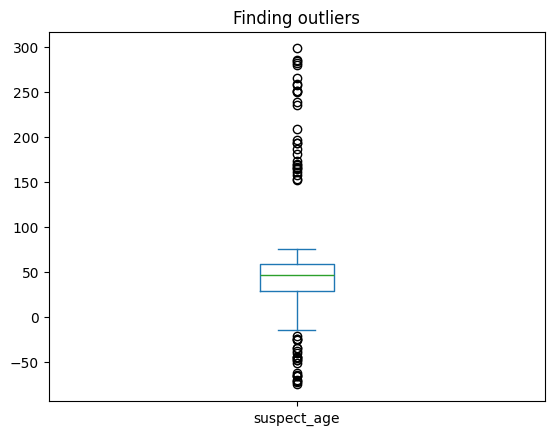

In [161]:
df['suspect_age'].dropna().plot(
    kind = "box",
    title = "Finding outliers"
)

plt.show()